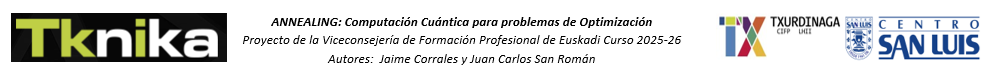

# Ejercicios básicos: QUBO con DADK

Este notebook contiene ejercicios de nivel inicial. Están pensados para aprender a formular QUBO paso a paso.

Cada ejercicio sigue esta estructura:

1. problema real;
2. variables binarias;
3. objetivo;
4. restricción o penalización;
5. explicación detallada de funciones DADK usadas;
6. código Python completo y comentado;
7. interpretación del resultado.

> Nota: se usa `QUBOSolverCPU` para resolver localmente. En un entorno con Digital Annealer, la formulación QUBO es la parte reutilizable.


> **Sin DADK instalado:** sustituye los `import` de `dadk` por
>
> ```python
> from mini_qubo import BinPol, Term, QUBOSolverCPU
> ```
>
> (`mini_qubo.py` debe estar en la misma carpeta). El resto del código funciona igual.


---
# Ejercicio básico 1 — Selección del mayor beneficio

### 1. Problema real

Tenemos **2 entidades**:

| Entidad | Beneficio |
|:---:|:---:|
| A | 3 |
| B | 2 |

**Restricción:** solo podemos elegir **exactamente una**.

**Pregunta:** ¿cuál debemos seleccionar para obtener el mayor beneficio?

La respuesta es evidente: elegir A. Pero el objetivo es ver cómo convertirlo en QUBO y cómo DADK lo resuelve.

---

### 2. Variables binarias

En QUBO todas las decisiones se expresan con variables binarias $x_i \in \{0,1\}$:

$x_A = 1 \Leftrightarrow \text{seleccionamos A}$

$x_B = 1 \Leftrightarrow \text{seleccionamos B}$

> **Propiedad fundamental de variables binarias:**  
> Como $x_i \in \{0,1\}$, se cumple que $x_i^2 = x_i$ (verificar: $0^2=0$, $1^2=1$).
> DADK aplica automáticamente esta simplificación al expandir expresiones cuadráticas.  
> Esto permite convertir términos cuadráticos en lineales y reduce la complejidad del polinomio.

---

### 3. Objetivo

Queremos maximizar:

$3x_A + 2x_B$

Como QUBO **siempre minimiza**, usamos el negativo. El razonamiento es:

$\text{maximizar}(f) \;\equiv\; \text{minimizar}(-f)$

Por tanto:

$H_{\text{objetivo}} = -(3x_A + 2x_B)$

Así, cuanto mayor sea el beneficio real de la solución, más negativa (más baja) será la energía $H$, y el solver lo favorecerá.

---

### 4. Restricción o penalización

Elegir exactamente una entidad:

$x_A + x_B = 1$

En QUBO no se separa la restricción. Se **convierte en una penalización** dentro de $H$:

$H_{\text{restricción}} = P\,(x_A + x_B - 1)^2$

La penalización vale **0** cuando se cumple y es **positiva** cuando no:

| Caso | $x_A + x_B$ | Penalización |
|---|:---:|:---:|
| Se elige exactamente una opción | 1 | 0 |
| No se elige ninguna | 0 | $P$ |
| Se eligen dos | 2 | $P$ |

**Expansión del término cuadrático** (aplicando $x^2=x$):

$P(x_A + x_B - 1)^2 = P(x_A + x_B - 2\,x_A x_B - 1)$

El término $x_A x_B$ es el único **cuadrático** genuino del problema; el resto son lineales.

---

### Elección del parámetro P

$P$ es el "peso" de la penalización. Debe ser lo suficientemente grande para que incumplir la restricción **nunca sea rentable**, pero no  para que el solver tenga dificultades numéricas.

$P > \text{mayor beneficio posible incumpliendo la restricción}$

En este ejercicio el beneficio máximo de un elemento es $3$, por tanto elegimos $P = 4 > 3$.

> **Advertencia:** si $P$ es demasiado pequeño, el solver puede devolver soluciones inválidas porque le resulta más "barato" incumplir la restricción que respetarla.

---

### Hamiltoniano completo

$H = -(3x_A + 2x_B) + 4\,(x_A + x_B - 1)^2$

**Verificación manual** (siempre recomendable antes de ejecutar el solver):

| $x_A$ | $x_B$ | Beneficio | ¿Cumple restricción? | $H$ |
|---:|---:|:---:|---|---:|
| 0 | 0 | 0 | No (no elige ninguna) | 4 |
| 1 | 0 | 3 | **Sí** | **−3** |
| 0 | 1 | 2 | **Sí** | −2 |
| 1 | 1 | 5 | No (elige dos) | −1 |

El menor valor es **−3**, por tanto la solución correcta es `x_A = 1`, `x_B = 0`.

> **Nota sobre la fila (1,1):** el beneficio real sería 5, pero la penalización ($P=4$) produce $H=-5+4=-1 > -3$. Esto demuestra que $P=4$ es suficiente para que la restricción sea prioritaria.


### 5. Funciones DADK usadas en este ejercicio

| Función / atributo | Uso en este ejercicio |
|---|---|
| `BinPol` | Clase que representa el polinomio QUBO. Permite construir expresiones con `+`, `-`, `*`, `**2` entre `Term` y escalares |
| `Term(1, 0)` | Crea la variable binaria `x_A`, asociada al índice de bit 0 |
| `Term(1, 1)` | Crea la variable binaria `x_B`, asociada al índice de bit 1 |
| `-beneficio_A * x_A` | Convierte la maximización del beneficio en minimización de energía (cambio de signo) |
| `(x_A + x_B - 1)**2` | Penaliza cualquier configuración que no elija exactamente una entidad; DADK expande y simplifica usando $x^2=x$ |
| `H.N` | Número de variables binarias presentes en el Hamiltoniano; debe ser 2 en este ejercicio |
| `H.compute(config)` | Evalúa el polinomio `H` en una configuración concreta; útil para separar la energía del objetivo y la penalización |
| `restriccion.compute(config)` | Evalúa solo la penalización; si es `0.0` la restricción se cumple exactamente |
| `objetivo.compute(config)` | Evalúa solo el objetivo; su valor negado es el beneficio real obtenido |
| `QUBOSolverCPU(...)` | Crea el solver local de DADK; útil para probar la formulación sin necesidad del Digital Annealer |
| `solver.minimize(H)` | Ejecuta el proceso de annealing y devuelve un objeto `SolutionList` con todas las soluciones encontradas |
| `solution_list.min_solution` | Recupera la solución con menor energía de todos los runs |
| `mejor.configuration[0]` | Lee el valor del bit 0, es decir el valor de `x_A` (0 ó 1) |
| `mejor.configuration[1]` | Lee el valor del bit 1, es decir el valor de `x_B` (0 ó 1) |
| `mejor.energy` | Valor mínimo de `H` alcanzado; si la restricción se cumple, `energy = −beneficio_total` |
| `mejor.frequency` | Número de runs que convergieron a esta misma solución; alta frecuencia indica solver estable |
| `solution_list.solutions` | Lista de todas las soluciones distintas encontradas, ordenadas de mejor (menor H) a peor |

**Parámetros principales de `QUBOSolverCPU`: (si no se define se usan valores por defecto)**

| Parámetro | Significado |
|---|---|
| `number_runs` | Número de ejecuciones independientes (mayor cobertura del espacio de soluciones) |
| `number_iterations` | Iteraciones de recocido por ejecución (más iteraciones → más refinamiento) |
| `scaling_bit_precision` | Precisión interna para escalar coeficientes (valor estándar: 48) |
| `temperature_start` | Temperatura inicial del proceso de annealing (controla la exploración inicial) |
| `temperature_end` | Temperatura final del proceso de annealing (controla la explotación al final) |
| `graphics=True` | Guarda datos internos para representar gráficamente la evolución del annealing |


In [16]:
# ── SECCIÓN 6: Código Python completo y comentado ──────────────────────────────
# Ejercicio 1 — Selección del mejor beneficio con QUBO y DADK 3.11
#
# OBJETIVO DEL EJERCICIO:
# Dadas dos entidades (A y B) con beneficio distinto, elegir EXACTAMENTE UNA
# que maximice el beneficio total. Es el caso más sencillo de optimización
# combinatoria binaria; sirve como base para entender la formulación QUBO.

# ── IMPORTAR DADK ─────────────────────────────────────────────────────────────
# BinPol : clase que representa un Polinomio Binario Cuadrático (QUBO).
#          Internamente almacena un diccionario de términos con sus coeficientes.
#          Admite operaciones aritméticas (+, -, *, **2) entre términos y escalares.
# Term   : representa el monomio  coeficiente × x_índice  (variable binaria).
#          Es la unidad mínima con la que se construye un QUBO.
from dadk.BinPol import BinPol, Term

# QUBOSolverCPU : emula en la CPU local el recocido del Digital Annealer (sin hardware DA).
# Útil para pruebas y problemas pequeños; la API es idéntica al solver real de Fujitsu.
from dadk.QUBOSolverCPU import QUBOSolverCPU

# ── DATOS DEL PROBLEMA ────────────────────────────────────────────────────────
beneficio_A = 3   # ganancia si se selecciona la entidad A
beneficio_B = 2   # ganancia si se selecciona la entidad B

# Parámetro de penalización P:
# Debe superar el beneficio máximo obtenible, se aplica si se inc la restricción.
# Si P es demasiado bajo, el solver prefiere incumplir la restricción (más barato).
# Regla práctica: P > max(beneficio_A, beneficio_B) = 3  →  elegimos P = 4.
P = 4

# ── VARIABLES BINARIAS ────────────────────────────────────────────────────────
# Term(coeficiente, índice_de_bit) crea la variable binaria x_índice con ese coef.
# En QUBO todas las variables son binarias: x ∈ {0, 1}.
# Índice 0 → x_A  (x_A = 1 si elegimos entidad A,  0 si no)
# Índice 1 → x_B  (x_B = 1 si elegimos entidad B,  0 si no)
x_A = Term(1, 0)
x_B = Term(1, 1)

# ── OBJETIVO ──────────────────────────────────────────────────────────────────
# Queremos MAXIMIZAR:  f = 3·x_A + 2·x_B
# El solver QUBO siempre MINIMIZA. Cambio de signo para convertir:
#   minimizar(−f)  ⟺  maximizar(f)
# H_obj = −3·x_A − 2·x_B
objetivo = -beneficio_A * x_A - beneficio_B * x_B

# ── RESTRICCIÓN ───────────────────────────────────────────────────────────────
# Exactamente una entidad seleccionada:  x_A + x_B = 1
#
# Técnica estándar en QUBO: penalización cuadrática
#   H_res = P · (x_A + x_B − 1)²
#
# Expansión (recordar que en binario x² = x, pues 0²=0 y 1²=1):
#   = P · (x_A + x_B − 2·x_A·x_B − 1)
#          ↑lineal      ↑cuadrático
#
# Verificación de los cuatro casos posibles:
#   (0,0) → (0+0−1)² = 1  → penaliza  ✗ (nada seleccionado)
#   (1,0) → (1+0−1)² = 0  → no penaliza ✓
#   (0,1) → (0+1−1)² = 0  → no penaliza ✓
#   (1,1) → (1+1−1)² = 1  → penaliza  ✗ (dos seleccionadas)
restriccion = P * (x_A + x_B - 1) ** 2

# ── HAMILTONIANO COMPLETO ─────────────────────────────────────────────────────
# H = H_objetivo + H_restricción
# El solver minimiza H; la solución factible con menor H es el óptimo global.
# Energía esperada: H(x_A=1, x_B=0) = −3 + 0 = −3  (la mejor)
H = objetivo + restriccion

print("Objetivo:    ", objetivo)
print("Restricción: ", restriccion)
print("Hamiltoniano H:", H)
print(f"Número de bits del problema: {H.N}")  # debe ser 2 (un bit por variable)

# ── SOLVER ────────────────────────────────────────────────────────────────────
# number_runs       : búsquedas independientes. Cada run parte de un estado
#                     aleatorio distinto → mayor cobertura del espacio de soluciones.
# number_iterations : pasos de annealing por run. Más pasos → más refinamiento.
# scaling_bit_precision : precisión interna de coeficientes (48 bits es estándar).
#
# ⚠️  NOTA sobre scaling_bit_precision y mejor.energy:
#   El solver escala internamente todos los coeficientes del QUBO a enteros de
#   'scaling_bit_precision' bits. El coeficiente más grande se lleva a ≈ 2^47 y
#   todos los demás se multiplican por el mismo factor (≈ 2^47 / coef_max).
#   Por eso mejor.energy devuelve un número enorme (p.ej. −52 771 280 477 433)
#   en lugar de −3.  Ese valor escalado SOLO sirve para comparar soluciones entre sí.
#   Para obtener la energía real en unidades del problema usa H.compute(config).
number_runs = 4
solver = QUBOSolverCPU(
    number_runs=number_runs,
    number_iterations=100,         # pocas iteraciones bastan para 2 bits
    scaling_bit_precision=48
)

# minimize(H) ejecuta el annealing y devuelve un objeto SolutionList.
# SolutionList agrupa todas las configuraciones distintas halladas,
# ordenadas de menor a mayor energía.
solution_list = solver.minimize(H)

# min_solution : la solución con la energía más baja (candidato a óptimo global).
mejor = solution_list.min_solution

# ── INTERPRETACIÓN DEL RESULTADO ──────────────────────────────────────────────
# configuration : dict {índice_bit: valor_binario} con la asignación óptima.
# Ejemplo:  {0: 1, 1: 0}  →  x_A=1 (seleccionada), x_B=0 (no seleccionada).
config = mejor.configuration
val_xA = config[0]   # bit 0 → estado de la variable x_A
val_xB = config[1]   # bit 1 → estado de la variable x_B
beneficio_total = beneficio_A * val_xA + beneficio_B * val_xB

print("\n" + "=" * 50)
print("RESULTADO")
print("=" * 50)
print(f"x_A = {val_xA} → Entidad A seleccionada: {'SÍ' if val_xA else 'NO'}")
print(f"x_B = {val_xB} → Entidad B seleccionada: {'SÍ' if val_xB else 'NO'}")
print(f"Beneficio total: {beneficio_total}")

# H.compute(config) evalúa el polinomio H en la configuración encontrada.
# Devuelve la energía REAL en unidades del problema (no la escalada internamente).
# Si la restricción se cumple (penalización = 0):  energy = −beneficio_total.
print(f"Energía mínima H: {H.compute(config)}")

# compute(config) evalúa el polinomio restriccion numéricamente.
# Debe ser 0.0 si la restricción se cumple; cualquier valor > 0 indica incumplimiento.
print(f"Penalización de restricción: {restriccion.compute(config)}")

# frequency : en cuántos de los number_runs se llegó a esta misma solución.
# Alta frecuencia indica convergencia robusta del solver al óptimo.
print(f"Frecuencia: {int(mejor.frequency)} de {number_runs} runs")
print(f"Restricción x_A+x_B=1: {'cumplida ✓' if val_xA + val_xB == 1 else 'INCUMPLIDA ✗'}")

# ── TABLA DE SOLUCIONES ENCONTRADAS ───────────────────────────────────────────
# solution_list.solutions lista TODAS las configuraciones distintas halladas,
# ordenadas de mejor (menor H) a peor. Permite analizar el "paisaje energético":
# cuántas soluciones factibles e infactibles encontró el solver y con qué frecuencia.
print("\nSoluciones encontradas por el solver:")
print(f"{'xA':>3} {'xB':>3} {'Beneficio':>10} {'H':>8} {'Frecuencia':>11}")
print("-" * 42)
for sol in solution_list.solutions:
    xa = sol.configuration[0]
    xb = sol.configuration[1]
    ben = beneficio_A * xa + beneficio_B * xb
    # H.compute() devuelve la energía real; sol.energy es la versión escalada internamente.
    print(f"{xa:>3} {xb:>3} {ben:>10} {H.compute(sol.configuration):>8.1f} {int(sol.frequency):>11}")

Objetivo:     - 3 bit_0 - 2 bit_1
Restricción:  4 - 4 bit_0 + 8 bit_0 bit_1 - 4 bit_1
Hamiltoniano H: 4 - 7 bit_0 + 8 bit_0 bit_1 - 6 bit_1
Número de bits del problema: 2

RESULTADO
x_A = 1 → Entidad A seleccionada: SÍ
x_B = 0 → Entidad B seleccionada: NO
Beneficio total: 3
Energía mínima H: -3
Penalización de restricción: 0
Frecuencia: 4 de 4 runs
Restricción x_A+x_B=1: cumplida ✓

Soluciones encontradas por el solver:
 xA  xB  Beneficio        H  Frecuencia
------------------------------------------
  1   0          3     -3.0           4


### 7. Interpretación del resultado

- **`x_A = 1`, `x_B = 0`** → el solver eligió la entidad **A**, con beneficio 3. Es la respuesta óptima y coincide con la verificación manual.
- **Energía H = −3** → el valor de la función hamiltoniana en la solución óptima. Coincide con la tabla: $H = -3·1 - 2·0 + 4·(1+0-1)^2 = -3$.
- **Penalización = 0** → la restricción $x_A + x_B = 1$ se cumple exactamente; la solución es **factible**.
- **Frecuencia** → si los 4 runs convergen al mismo resultado, el solver es estable para este problema sencillo.

> **Claves de verificación:**
> 1. `mejor.energy` debe ser negativo (beneficio capturado en la energía).
> 2. `restriccion.compute(config)` debe ser `0.0` (restricción respetada).
> 3. `val_xA + val_xB` debe ser `1` (exactamente una entidad elegida).
> 4. `−mejor.energy` debe igualar el `beneficio_total` (cuando penalización = 0).

---

### Relación con el Digital Annealer

El flujo de trabajo es **idéntico** independientemente de si se usa `QUBOSolverCPU` (local) o el Digital Annealer de Fujitsu:

```text
Problema real → variables binarias → H QUBO → solver → configuración binaria → interpretación
```

`QUBOSolverCPU` permite verificar la formulación sin acceso al hardware. Una vez comprobado que `H` está bien construido, el mismo código puede ejecutarse en el Digital Annealer cambiando únicamente el solver.


---
# Ejercicio básico 2 — Mochila de capacidad limitada

### 1. Problema real

Tenemos una mochila con **capacidad máxima 5**. Queremos seleccionar elementos con el mayor valor posible sin superar esa capacidad.

| Elemento | Valor | Peso |
|---|:---:|:---:|
| Router | 8 | 3 |
| Switch | 6 | 2 |
| Punto de acceso | 5 | 2 |
| Cableado | 4 | 1 |

---

### 2. Variables binarias

Una variable por elemento ($i = 0, 1, 2, 3$):

$x_i = 1 \Leftrightarrow \text{el elemento } i \text{ entra en la mochila}$

---

### 3. Objetivo

Maximizar el valor total:

$8x_0 + 6x_1 + 5x_2 + 4x_3$

En QUBO (minimizar el negativo):

$H_{\text{objetivo}} = -(8x_0 + 6x_1 + 5x_2 + 4x_3)$

---

### 4. Restricción o penalización

La capacidad exige:

$3x_0 + 2x_1 + 2x_2 + x_3 \leq 5$

Para convertir una **desigualdad** en QUBO introducimos una variable de **holgura** $s$ que representa el espacio libre restante:

$s = y_0 + 2y_1 + 4y_2 \quad (y_0, y_1, y_2 \in \{0,1\})$

Con tres bits se pueden representar los valores $0, 1, \ldots, 7$, suficiente para cubrir hasta 5 de holgura. La desigualdad se convierte en igualdad:

$3x_0 + 2x_1 + 2x_2 + x_3 + s = 5$

Penalización:

$H_{\text{restricción}} = P\,(3x_0 + 2x_1 + 2x_2 + x_3 + y_0 + 2y_1 + 4y_2 - 5)^2$

Elegimos `P = 30`, superior al valor máximo total `23`, de modo que superar la capacidad nunca resulte rentable.


### 5. Funciones DADK usadas en este ejercicio

| Función / atributo | Uso en la mochila |
|---|---|
| `Term(1, i)` | Crea la variable binaria de cada elemento (`i` de 0 a 3) |
| `Term(1, 4)`, `Term(1, 5)`, `Term(1, 6)` | Crean los bits de holgura `y0`, `y1`, `y2` |
| `slack = y0 + 2*y1 + 4*y2` | Codifica con bits binarios el espacio libre de la mochila |
| `BinPol.sum(...)` | Suma automáticamente términos sobre todos los elementos |
| `-valores[i] * x[i]` | Cambia maximización de valor a minimización (negativo) |
| `pesos[i] * x[i]` | Calcula el peso acumulado de los elementos seleccionados |
| `(peso_total + slack - capacidad)**2` | Penaliza cualquier solución que no cuadre con la capacidad |
| `objetivo.compute(config)` | Evalúa solo la parte de valor, separada de la penalización |
| `restriccion.compute(config)` | Comprueba si la penalización quedó a cero (restricción cumplida) |
| `H.N` | Número total de bits: 4 elementos + 3 holgura = 7 |


In [17]:
# ── SECCIÓN 6: Código Python completo y comentado ──────────────────────────────
# Ejercicio 2 — Mochila pequeña con DADK 3.11
#
# OBJETIVO DEL EJERCICIO:
# Seleccionar un subconjunto de elementos (equipos de red) maximizando el valor
# total sin superar la capacidad de la mochila (peso máximo permitido).
# Es el problema de la mochila 0/1 (Knapsack), NP-difícil en su forma general.
#
from dadk.BinPol import BinPol, Term
from dadk.QUBOSolverCPU import QUBOSolverCPU

# ── DATOS ─────────────────────────────────────────────────────────────────────
# Cada elemento tiene un valor (beneficio) y un peso (recurso consumido).
elementos = ["Router", "Switch", "Punto de acceso", "Cableado"]
valores   = [8, 6, 5, 4]   # valor/utilidad de cada elemento
pesos     = [3, 2, 2, 1]   # peso/recurso que consume cada elemento
capacidad = 5              # límite máximo de peso total admitido

# P debe ser mayor que el valor máximo alcanzable (suma de todos los valores = 23).
# Si P es pequeño el solver puede obtener más beneficio ignorando la restricción.
P = 30  # 30 > 23 (suma total de valores) → penalización dominante

# Número de elementos del problema
n = len(elementos)

# ── VARIABLES DE ELEMENTOS ────────────────────────────────────────────────────
# x[i] = 1 → el elemento i SE INCLUYE en la mochila
# x[i] = 0 → el elemento i NO SE INCLUYE
# Bits 0..n-1 representan las decisiones sobre los elementos.
# x[0] → Router  |  x[1] → Switch  |  x[2] → Punto de acceso  |  x[3] → Cableado
x = [Term(1, i) for i in range(n)]

# ── VARIABLES DE HOLGURA (SLACK) ──────────────────────────────────────────────
# Problema: la restricción  Σ pesos·x_i ≤ capacidad  es una DESIGUALDAD.
# QUBO solo puede representar igualdades de forma directa.
# Solución: introducir una variable entera de holgura  s  tal que:
#   Σ pesos·x_i + s = capacidad   (convierte ≤ en =)
# La holgura representa el espacio libre restante en la mochila.
#
# Codificación binaria de s ∈ [0, capacidad]:
#   s = y0·1 + y1·2 + y2·4   (representación binaria con 3 bits)
#   Rango posible: 0..7  (cubre 0..capacidad=5 con margen).
#
# ¿Por qué 3 bits?  ceil(log2(capacidad + 1)) = ceil(log2(6)) = 3.
# Los índices de estos bits siguen a los de los elementos (4, 5, 6).
y0 = Term(1, 4)   # bit 4: peso 1 (2⁰)
y1 = Term(1, 5)   # bit 5: peso 2 (2¹)
y2 = Term(1, 6)   # bit 6: peso 4 (2²)
slack = y0 + 2*y1 + 4*y2   # valor entero que representa la holgura

# ── OBJETIVO ──────────────────────────────────────────────────────────────────
# Maximizar Σ valores[i]·x[i]  →  minimizar el negativo (conversión QUBO estándar).
# BinPol.sum() es equivalente a Python sum() pero opera sobre objetos BinPol/Term.
objetivo = BinPol.sum(-valores[i] * x[i] for i in range(n))

# ── RESTRICCIÓN DE CAPACIDAD ──────────────────────────────────────────────────
# Penalización cuadrática de la igualdad:  peso_total + slack = capacidad
#   H_res = P · (Σ pesos[i]·x[i] + slack − capacidad)²
#
# Cuando se cumple la igualdad el cuadrado vale 0  →  sin penalización.
# Cuando se incumple (se excede la capacidad o la holgura no cuadra) el término
# cuadrático introduce una energía positiva que el solver evita.
peso_total  = BinPol.sum(pesos[i] * x[i] for i in range(n))
restriccion = P * (peso_total + slack - capacidad) ** 2

# ── HAMILTONIANO ──────────────────────────────────────────────────────────────
# H total = objetivo + restricción
# El espacio de búsqueda tiene 2^7 = 128 configuraciones posibles (4 elementos + 3 bits slack).
H = objetivo + restriccion

print(f"Hamiltoniano creado con {H.N} bits")
print("Bits 0-3: elementos | Bits 4-6: holgura (slack)")

# ── SOLVER ────────────────────────────────────────────────────────────────────
# Aumentamos number_runs e iterations respecto al Ejercicio 1 porque el espacio
# de búsqueda es mayor (7 bits = 128 combinaciones vs. 2 bits = 4 combinaciones).
number_runs = 12
solver = QUBOSolverCPU(
    number_runs=number_runs,
    number_iterations=800,    # más iteraciones para explorar mejor el espacio
    scaling_bit_precision=48
)
solution_list = solver.minimize(H)
mejor         = solution_list.min_solution
config        = mejor.configuration   # dict {bit_index: 0_o_1}

# ── INTERPRETACIÓN DEL RESULTADO ──────────────────────────────────────────────
# Reconstruimos qué elementos se seleccionaron leyendo los bits 0..n-1.
seleccionados  = [elementos[i] for i in range(n) if config[i] == 1]
valor_obtenido = sum(valores[i] for i in range(n) if config[i] == 1)
peso_obtenido  = sum(pesos[i]   for i in range(n) if config[i] == 1)

# Reconstruimos el valor de la holgura a partir de los bits 4-6.
# config[4]·1 + config[5]·2 + config[6]·4 debe igualar (capacidad - peso_obtenido).
slack_obtenido = config[4] + 2*config[5] + 4*config[6]

print("\nRESULTADO MOCHILA")
print("=" * 60)
print(f"Elementos seleccionados : {seleccionados}")
print(f"Valor obtenido          : {valor_obtenido}")
print(f"Peso utilizado          : {peso_obtenido} / {capacidad}")
print(f"Holgura codificada      : {slack_obtenido}  (espacio libre en la mochila)")
# Verificación: peso + holgura debe ser exactamente igual a la capacidad.
print(f"Restricción (peso+slack = capacidad): {peso_obtenido}+{slack_obtenido} = {peso_obtenido+slack_obtenido}  ({'✓' if peso_obtenido+slack_obtenido==capacidad else '✗'})")
# H.compute(config) devuelve la energía real del problema (no la escalada internamente).
print(f"Energía H               : {H.compute(config)}")
# Penalización 0.0 confirma que la restricción de capacidad se respeta exactamente.
print(f"Penalización            : {restriccion.compute(config)}")
print(f"Frecuencia              : {int(mejor.frequency)} de {number_runs} runs")

# ── TABLA RESUMEN ─────────────────────────────────────────────────────────────
# Muestra las 8 mejores soluciones halladas para comparar factibles vs. infactibles.
# Las soluciones con Penaliz. = 0 son las únicas que respetan la capacidad.
print("\nSoluciones encontradas (top 8):")
print(f"{'Bits':>7} {'Valor':>7} {'Peso':>6} {'Slack':>7} {'Penaliz.':>9} {'H':>8} {'Freq':>6}")
print("-" * 56)
for sol in solution_list.solutions[:8]:
    cfg  = sol.configuration
    # Bits 0-3: elementos incluidos (1) o excluidos (0)
    bits = ''.join(str(cfg[i]) for i in range(n))
    val  = sum(valores[i] for i in range(n) if cfg[i] == 1)
    pes  = sum(pesos[i]   for i in range(n) if cfg[i] == 1)
    sl   = cfg[4] + 2*cfg[5] + 4*cfg[6]   # valor de holgura decodificado
    pen  = restriccion.compute(cfg)         # 0.0 → factible, >0 → infactible
    # H.compute() devuelve la energía real; sol.energy es la versión escalada internamente.
    print(f"{bits:>7} {val:>7} {pes:>6} {sl:>7} {pen:>9.1f} {H.compute(sol.configuration):>8.1f} {int(sol.frequency):>6}")

Hamiltoniano creado con 7 bits
Bits 0-3: elementos | Bits 4-6: holgura (slack)

RESULTADO MOCHILA
Elementos seleccionados : ['Switch', 'Punto de acceso', 'Cableado']
Valor obtenido          : 15
Peso utilizado          : 5 / 5
Holgura codificada      : 0  (espacio libre en la mochila)
Restricción (peso+slack = capacidad): 5+0 = 5  (✓)
Energía H               : -15
Penalización            : 0
Frecuencia              : 12 de 12 runs

Soluciones encontradas (top 8):
   Bits   Valor   Peso   Slack  Penaliz.        H   Freq
--------------------------------------------------------
   0111      15      5       0       0.0    -15.0     12


### 7. Interpretación del resultado

- **Elementos seleccionados**: la combinación óptima es **Switch + Punto de acceso + Cableado** (valor 6+5+4 = **15**, peso 2+2+1 = 5 = capacidad exacta). Otras soluciones factibles son peores: Router + Switch (valor 14, peso 5) o Router + Punto de acceso (valor 13, peso 5). *(Corregido: la versión anterior indicaba Router + Switch como óptimo.)*
- **Peso + holgura = capacidad**: si este valor no es 5, la solución es infactible (penalización > 0).
- **Penalización = 0**: confirma que la restricción de capacidad se respeta exactamente.
- **Energía H**: debe ser negativa (−valor_obtenido). Cuanto más negativa, mejor la solución.
- **Bits de holgura**: los bits 4-6 codifican el espacio libre. Por ejemplo, si peso = 5 → holgura = 0 → `y0=y1=y2=0`.

> **Claves de verificación:**
> 1. `restriccion.compute(config)` debe ser `0.0`.
> 2. `peso_obtenido ≤ capacidad` (restricción cumplida).
> 3. `mejor.energy = -valor_obtenido` (solo si la penalización es 0).


---
# Ejercicio básico 3 — Problema del viajante (TSP) con 4 ciudades

### 1. Problema real

Queremos encontrar el **recorrido de menor coste** que visite 4 ciudades exactamente una vez y vuelva al origen (problema del viajante de comercio, TSP).

Matriz de distancias:

| De / A | A | B | C | D |
|---|---:|---:|---:|---:|
| A | 0 | 4 | 7 | 3 |
| B | 4 | 0 | 2 | 6 |
| C | 7 | 2 | 0 | 5 |
| D | 3 | 6 | 5 | 0 |

---

### 2. Variables binarias

Se usa una variable por pareja **(ciudad, posición)**:

$x_{c,p} = 1 \Leftrightarrow \text{la ciudad } c \text{ ocupa la posición } p \text{ del recorrido}$

Con 4 ciudades y 4 posiciones se necesitan **16 variables** ($x_{0,0}, x_{0,1}, \ldots, x_{3,3}$).

El índice lineal del bit es: $\text{idx}(c, p) = c \cdot 4 + p$

---

### 3. Objetivo

Minimizar la suma de distancias entre ciudades consecutivas en el ciclo:

$H_{\text{objetivo}} = \sum_{p=0}^{3} \sum_{i \neq j} d_{ij}\, x_{i,p}\, x_{j,\,(p+1)\,\bmod\,4}$

---

### 4. Restricción o penalización

Se necesitan dos restricciones para que la asignación sea válida:

**R1 — En cada posición exactamente una ciudad:**

$\sum_c x_{c,p} = 1 \quad \forall p$

**R2 — Cada ciudad aparece exactamente una vez:**

$\sum_p x_{c,p} = 1 \quad \forall c$

Penalización combinada (con `P = 100`, mucho mayor que cualquier distancia):

$H_{\text{restricción}} = P\left[\sum_p\left(\sum_c x_{c,p}-1\right)^2 + \sum_c\left(\sum_p x_{c,p}-1\right)^2\right]$


### 5. Funciones DADK usadas en este ejercicio

| Función / atributo | Uso en el TSP |
|---|---|
| `idx(ciudad, posicion)` | Convierte una pareja `(c, p)` en un índice entero de bit ($c \cdot n + p$) |
| `Term(1, idx(c, p))` | Crea la variable $x_{c,p}$ |
| `x(i,p) * x(j,p_siguiente)` | Término cuadrático que representa viajar de la ciudad `i` a la `j` |
| `BinPol.sum(...)` | Suma todos los costes de aristas y todas las penalizaciones |
| `(sum_c - 1)**2` | Penaliza posiciones vacías o con varias ciudades a la vez |
| `(sum_p - 1)**2` | Penaliza ciudades repetidas o no visitadas |
| `(p + 1) % n` | Cierra el ciclo: la posición siguiente a la última es la primera |
| `configuration[idx(c,p)]` | Lee si la ciudad `c` aparece en la posición `p` |
| `H.N` | Verifica que el modelo tiene exactamente 16 bits ($4 \times 4$) |


In [18]:
# ── SECCIÓN 6: Código Python completo y comentado ──────────────────────────────
# Ejercicio 3 — TSP de 4 ciudades con DADK 3.11
#
# OBJETIVO DEL EJERCICIO:
# Encontrar el ciclo hamiltoniano de menor coste que visita 4 ciudades exactamente
# una vez y regresa al origen (Travelling Salesman Problem, TSP).
# El TSP es NP-completo; para 4 ciudades hay (4-1)!/2 = 3 rutas distintas.
#
# Analogía en incumplir: optimizar la ruta de visitas a distintos centros de datos
# (o nodos de red) minimizando la latencia/coste total del recorrido.

from dadk.BinPol import BinPol, Term
from dadk.QUBOSolverCPU import QUBOSolverCPU

# ── DATOS ─────────────────────────────────────────────────────────────────────
ciudades = ["A", "B", "C", "D"]   # 4 nodos del grafo completo

# Matriz de distancias (simétrica): distancias[i][j] = coste de viajar de i a j.
# En redes: podría representar latencia, coste de enlace o distancia física.
distancias = [
    [0, 4, 7, 3],   # desde A: a B=4, a C=7, a D=3
    [4, 0, 2, 6],   # desde B: a A=4, a C=2, a D=6
    [7, 2, 0, 5],   # desde C: a A=7, a B=2, a D=5
    [3, 6, 5, 0],   # desde D: a A=3, a B=6, a C=5
]
n = len(ciudades)   # n = 4

# P debe ser mucho mayor que la distancia máxima del ciclo (peor caso ≈ 4·7 = 28).
# Elegimos P = 100 >> 28 para garantizar que las restricciones dominen al objetivo.
P = 100

# ── FUNCIONES DE ÍNDICE ───────────────────────────────────────────────────────
# El TSP usa n×n variables binarias x_{ciudad, posición}.
# Para operar con vectores planos de bits necesitamos una función de mapeo:
#   idx(c, p)  →  índice lineal del bit correspondiente a (ciudad c, posición p)
#
# Esquema de indexación (n=4):
#   posición →   0    1    2    3
#   ciudad A:  bit0  bit1  bit2  bit3
#   ciudad B:  bit4  bit5  bit6  bit7
#   ciudad C:  bit8  bit9  bit10 bit11
#   ciudad D: bit12 bit13 bit14 bit15
# Total: n×n = 4×4 = 16 bits.
def idx(c, p):
    """Convierte la pareja (ciudad c, posición p) en un índice lineal de bit."""
    return c * n + p

# x(c, p) devuelve el Term (variable binaria) x_{c,p}.
# x_{c,p} = 1 significa "la ciudad c ocupa la posición p en la ruta".
def x(c, p):
    return Term(1, idx(c, p))

# ── OBJETIVO: DISTANCIA TOTAL DEL CICLO ───────────────────────────────────────
# Para cada posición p del ciclo, si la ciudad i está en p y la j en p+1,
# se acumula el coste distancias[i][j].
# El operador % cierra el ciclo: la posición siguiente a la última (n-1) es la 0.
#
# Término cuadrático:  distancias[i][j] · x(i,p) · x(j,(p+1)%n)
# Solo contribuye cuando x(i,p)=1 AND x(j,p+1)=1 simultáneamente.
objetivo = BinPol.sum(
    distancias[i][j] * x(i, p) * x(j, (p + 1) % n)
    for p in range(n)      # para cada posición del ciclo
    for i in range(n)      # ciudad en la posición actual
    for j in range(n)      # ciudad en la posición siguiente
    if i != j              # excluir auto-loops (una ciudad no va a sí misma)
)

# ── RESTRICCIÓN 1: EXACTAMENTE UNA CIUDAD POR POSICIÓN ───────────────────────
# Cada posición del ciclo debe estar ocupada por exactamente una ciudad.
# Para la posición p:  Σ_c x_{c,p} = 1
# Penalización:  P · (Σ_c x_{c,p} − 1)²
# Si hay 0 o 2+ ciudades en la misma posición el término cuadrático es positivo.
r1 = BinPol.sum(
    (BinPol.sum(x(c, p) for c in range(n)) - 1) ** 2
    for p in range(n)   # una restricción por cada posición del ciclo
)

# ── RESTRICCIÓN 2: CADA CIUDAD APARECE EXACTAMENTE UNA VEZ ───────────────────
# Cada ciudad debe aparecer en exactamente una posición del ciclo.
# Para la ciudad c:  Σ_p x_{c,p} = 1
# Penalización:  P · (Σ_p x_{c,p} − 1)²
# Si una ciudad no aparece o aparece repetida, el término cuadrático es positivo.
r2 = BinPol.sum(
    (BinPol.sum(x(c, p) for p in range(n)) - 1) ** 2
    for c in range(n)   # una restricción por cada ciudad
)

# Combinamos las dos restricciones y escalamos con P.
# r1 + r2 garantiza que la solución codifique una permutación válida.
restricciones = P * (r1 + r2)

# ── HAMILTONIANO ──────────────────────────────────────────────────────────────
H = objetivo + restricciones

# Verificamos que el Hamiltoniano tiene exactamente n×n = 16 bits.
print(f"Hamiltoniano TSP creado con {H.N} bits (esperado: {n*n})")

# ── SOLVER ────────────────────────────────────────────────────────────────────
# El espacio de búsqueda es 2^16 = 65536 configuraciones.
# Solo n! = 24 son permutaciones válidas; el resto son infactibles.
# Aumentamos number_iterations para explorar mejor este espacio más grande.
number_runs = 16
solver = QUBOSolverCPU(
    number_runs=number_runs,
    number_iterations=2000,    # más iteraciones para problema de 16 bits
    scaling_bit_precision=48
)
solution_list = solver.minimize(H)
mejor  = solution_list.min_solution
config = mejor.configuration   # dict con 16 bits

# ── DECODIFICAR RUTA ──────────────────────────────────────────────────────────
# Recorremos cada posición p y buscamos qué ciudad tiene x_{c,p} = 1.
# Si la solución es válida, cada posición tendrá exactamente una ciudad asignada.
ruta_indices = []
for p in range(n):
    ciudad_en_p = None
    for c in range(n):
        if config[idx(c, p)] == 1:
            ciudad_en_p = c   # ciudad c está en la posición p
    ruta_indices.append(ciudad_en_p)

# Convertimos índices numéricos a nombres de ciudades.
ruta = [ciudades[c] if c is not None else "?" for c in ruta_indices]

# Validamos la ruta: debe contener las n ciudades sin repetición ni huecos.
ruta_valida = all(c is not None for c in ruta_indices) and len(set(ruta_indices)) == n

# Calculamos la distancia real del ciclo solo si la ruta es válida.
distancia_total = 0
if ruta_valida:
    for p in range(n):
        origen  = ruta_indices[p]
        destino = ruta_indices[(p + 1) % n]   # el último nodo vuelve al primero
        distancia_total += distancias[origen][destino]

print("\nRESULTADO TSP")
print("=" * 60)
# Mostramos la ruta como ciclo: última ciudad vuelve a la primera.
print("Ruta:", " → ".join(ruta + [ruta[0]]))
print(f"Ruta válida      : {'sí ✓' if ruta_valida else 'no ✗'}")
print(f"Distancia total  : {distancia_total}")
# Penalización = 0 confirma que las dos restricciones (posición y ciudad) se cumplen.
print(f"Penalización     : {restricciones.compute(config)}")
# H.compute(config) devuelve la energía real del problema (no la escalada internamente).
print(f"Energía H        : {H.compute(config)}")
print(f"Frecuencia       : {int(mejor.frequency)} de {number_runs} runs")

# ── MATRIZ CIUDAD-POSICIÓN ────────────────────────────────────────────────────
# La matriz x_{ciudad, posición} debe ser una matriz de permutación:
# exactamente un 1 por fila y por columna si la solución es válida.
# Cualquier fila o columna con más o menos de un 1 indica solución infactible.
print("\nMatriz x_{ciudad, posición}:")
print("        " + "  ".join(f"pos{p}" for p in range(n)))
for c in range(n):
    fila = [str(config[idx(c, p)]) for p in range(n)]
    print(f"  {ciudades[c]:>3}:  " + "     ".join(fila))

Hamiltoniano TSP creado con 16 bits (esperado: 16)

RESULTADO TSP
Ruta: C → D → A → B → C
Ruta válida      : sí ✓
Distancia total  : 14
Penalización     : 0
Energía H        : 14
Frecuencia       : 1 de 16 runs

Matriz x_{ciudad, posición}:
        pos0  pos1  pos2  pos3
    A:  0     0     1     0
    B:  0     0     0     1
    C:  1     0     0     0
    D:  0     1     0     0


### 7. Interpretación del resultado

- **Ruta válida = sí**: todas las posiciones tienen exactamente una ciudad y ninguna ciudad se repite. Si es `no`, la penalización no fue suficiente o se necesitan más iteraciones.
- **Distancia total**: la ruta óptima para esta matriz es **A→B→C→D→A** con distancia $4+2+5+3=14$ (o cualquier rotación/inversión equivalente, p. ej. C→D→A→B→C). Las otras rutas posibles miden 18 (A→C→B→D→A) y 22 (A→B→D→C→A). *(Corregido: la versión anterior indicaba 18 como óptimo.)*
- **Penalización = 0**: confirma que las dos restricciones (una ciudad por posición y cada ciudad una vez) se cumplen.
- **Energía H = distancia_total** cuando la penalización es 0, ya que el objetivo es la distancia (no está negado, se minimiza directamente).
- **Matriz ciudad-posición**: debe tener exactamente un `1` por fila y por columna (permutación).

> **Claves de verificación:**
> 1. `restricciones.compute(config)` debe ser `0.0`.
> 2. La suma de cada fila y columna de la matriz debe ser `1`.
> 3. `distancia_total` coincide con la suma de aristas del ciclo decodificado.


---
# Ejercicio básico 4 — Max-Cut de 7 nodos

### 1. Problema real

Tenemos un **grafo con 7 nodos**. Queremos dividir los nodos en dos grupos (A y B) de forma que el mayor número posible de aristas quede **cortada** entre los dos grupos.

Aristas del grafo (10 aristas):

```
0 — 1    0 — 2
1 — 3    1 — 4
2 — 3    2 — 5
3 — 6
4 — 5    4 — 6
5 — 6
```

El grafo tiene un ciclo impar de longitud 5: **0 — 1 — 4 — 5 — 2 — 0**, lo que impide una bipartición perfecta (cortar las 10 aristas). El máximo corte teórico es **9**.

---

### 2. Variables binarias

Una variable por nodo ($i = 0, \ldots, 6$):

$x_i = 0 \Rightarrow \text{nodo } i \text{ en grupo A}$

$x_i = 1 \Rightarrow \text{nodo } i \text{ en grupo B}$

Con 7 nodos hay $2^7 = 128$ posibles particiones (sin contar simetría).

---

### 3. Objetivo

Una arista $(i, j)$ está **cortada** si sus extremos están en grupos distintos:

$x_i + x_j - 2\,x_i x_j$

| $x_i$ | $x_j$ | ¿Arista cortada? | Fórmula |
|---:|---:|---|:---:|
| 0 | 0 | No (mismo grupo A) | 0 |
| 0 | 1 | **Sí** | 1 |
| 1 | 0 | **Sí** | 1 |
| 1 | 1 | No (mismo grupo B) | 0 |

Queremos **maximizar** el número de aristas cortadas. En QUBO minimizamos el negativo:

$H = -\sum_{(i,j) \in E}\left(x_i + x_j - 2\,x_i x_j\right)$

---

### 4. Restricción o penalización

**Este ejercicio no tiene restricciones adicionales.** Todo el hamiltoniano es objetivo puro. Cualquier partición binaria es válida; simplemente buscamos la que maximiza el corte.

### 5. Funciones DADK usadas en este ejercicio

| Función / atributo | Uso en Max-Cut |
|---|---|
| `Term(1, i)` | Crea una variable binaria por nodo (índice = número de nodo) |
| `x[i] + x[j] - 2*x[i]*x[j]` | Expresión cuadrática que vale 1 si la arista está cortada, 0 si no |
| `BinPol.sum(...)` | Suma la contribución de todas las aristas del grafo |
| `-BinPol.sum(...)` | Convierte la maximización de corte en minimización |
| `solver.minimize(H)` | Busca la partición de nodos con más aristas cortadas |
| `configuration[i]` | Indica el grupo del nodo `i`: `0` → grupo A, `1` → grupo B |
| `solution_list.solutions` | Permite ver todas las particiones encontradas y comparar cortes |

> Este ejercicio es especialmente útil para iniciarse porque **no necesita penalizaciones**: todo el QUBO es función objetivo.


In [19]:
# ── SECCIÓN 6: Código Python completo y comentado ──────────────────────────────
# Ejercicio 4 — Max-Cut con DADK 3.11
#
# OBJETIVO DEL EJERCICIO:
# Dado un grafo no dirigido, dividir sus nodos en dos grupos (A y B) de modo
# que se maximice el número de aristas que cruzan la frontera entre grupos
# (aristas "cortadas"). Max-Cut es NP-completo en grafos generales.
#

from dadk.BinPol import BinPol, Term
from dadk.QUBOSolverCPU import QUBOSolverCPU

# ── DATOS ─────────────────────────────────────────────────────────────────────
nodos = [0, 1, 2, 3, 4, 5, 6]   # 7 nodos del grafo

# 10 aristas no dirigidas. El grafo tiene ciclo impar 0-1-4-5-2-0 (longitud 5)
# → NO es bipartito → no es posible cortar las 10 aristas (máximo teórico = 9).
aristas = [
    (0, 1), (0, 2),           # nodo 0 conecta con 1 y 2
    (1, 3), (1, 4),           # nodo 1 conecta con 3 y 4
    (2, 3), (2, 5),           # nodo 2 conecta con 3 y 5
    (3, 6),                   # nodo 3 conecta con 6
    (4, 5), (4, 6),           # nodo 4 conecta con 5 y 6
    (5, 6),                   # nodo 5 conecta con 6
]

# ── VARIABLES BINARIAS ────────────────────────────────────────────────────────
# x[i] = 0 → nodo i pertenece al GRUPO A
# x[i] = 1 → nodo i pertenece al GRUPO B
# No hay penalizaciones; cualquier asignación binaria es factible.
x = [Term(1, i) for i in nodos]

# ── OBJETIVO ──────────────────────────────────────────────────────────────────
# Para cada arista (i, j), la expresión  x_i + x_j − 2·x_i·x_j  vale:
#   i∈A(0), j∈A(0):  0 + 0 − 0 = 0  → arista no cortada (mismo grupo)
#   i∈A(0), j∈B(1):  0 + 1 − 0 = 1  → arista cortada    (grupos distintos) ✓
#   i∈B(1), j∈A(0):  1 + 0 − 0 = 1  → arista cortada    (grupos distintos) ✓
#   i∈B(1), j∈B(1):  1 + 1 − 2 = 0  → arista no cortada (mismo grupo)
#
# Equivale a XOR lógico: la arista se corta si y solo si los bits de sus extremos difieren.
#
# Queremos MAXIMIZAR el número de aristas cortadas → MINIMIZAMOS el negativo.
corte = BinPol.sum(x[i] + x[j] - 2 * x[i] * x[j] for i, j in aristas)
H = -corte   # minimizar(−corte) ⟺ maximizar(corte)

print(f"Hamiltoniano Max-Cut creado con {H.N} bits")
print(f"Número de aristas: {len(aristas)}  |  Máximo corte teórico: {len(aristas) - 1}")

# ── SOLVER ────────────────────────────────────────────────────────────────────
# 7 bits → 2^7 = 128 configuraciones posibles.
# Sin restricciones, cualquier configuración es válida; solo varía el corte.
number_runs = 12
solver = QUBOSolverCPU(
    number_runs=number_runs,
    number_iterations=800,   # suficiente para explorar 128 combinaciones
    scaling_bit_precision=48
)
solution_list = solver.minimize(H)
mejor  = solution_list.min_solution
config = mejor.configuration   # dict {bit: 0_o_1} con la partición óptima

# ── INTERPRETACIÓN DEL RESULTADO ──────────────────────────────────────────────
# Separamos los nodos en grupo A (bit=0) y grupo B (bit=1).
grupo_A          = [i for i in nodos if config[i] == 0]
grupo_B          = [i for i in nodos if config[i] == 1]

# Una arista está cortada cuando sus dos extremos pertenecen a grupos distintos.
aristas_cortadas = [(i, j) for i, j in aristas if config[i] != config[j]]

print("\nRESULTADO MAX-CUT")
print("=" * 60)
print(f"Grupo A: nodos {grupo_A}")
print(f"Grupo B: nodos {grupo_B}")
print(f"Aristas cortadas          : {aristas_cortadas}")
print(f"Número de aristas cortadas: {len(aristas_cortadas)} de {len(aristas)}")

# H.compute(config) devuelve la energía real (= −número de aristas cortadas).
print(f"Energía H                 : {H.compute(config)}  (= −{len(aristas_cortadas)})")
print(f"Frecuencia                : {int(mejor.frequency)} de {number_runs} runs")

# ── TABLA DE SOLUCIONES ────────────────────────────────────────────────────────
# Nota sobre simetría: los pares complementarios (invertir todos los bits)
# producen exactamente el mismo corte → verás duplicados con energía idéntica.
print("\nSoluciones encontradas:")
print(f"{'bits':>8} {'grupo A':>16} {'grupo B':>16} {'corte':>6} {'H':>8} {'freq':>6}")
print("-" * 66)
for sol in solution_list.solutions[:10]:
    cfg  = sol.configuration
    gA   = [i for i in nodos if cfg[i] == 0]
    gB   = [i for i in nodos if cfg[i] == 1]
    cut  = sum(1 for i, j in aristas if cfg[i] != cfg[j])
    bits = ''.join(str(cfg[i]) for i in nodos)
    print(f"{bits:>8} {str(gA):>16} {str(gB):>16} {cut:>6} {H.compute(sol.configuration):>8.1f} {int(sol.frequency):>6}")

Hamiltoniano Max-Cut creado con 7 bits
Número de aristas: 10  |  Máximo corte teórico: 9

RESULTADO MAX-CUT
Grupo A: nodos [0, 3, 4, 5]
Grupo B: nodos [1, 2, 6]
Aristas cortadas          : [(0, 1), (0, 2), (1, 3), (1, 4), (2, 3), (2, 5), (3, 6), (4, 6), (5, 6)]
Número de aristas cortadas: 9 de 10
Energía H                 : -9  (= −9)
Frecuencia                : 7 de 12 runs

Soluciones encontradas:
    bits          grupo A          grupo B  corte        H   freq
------------------------------------------------------------------
 0110001     [0, 3, 4, 5]        [1, 2, 6]      9     -9.0      7
 1001110        [1, 2, 6]     [0, 3, 4, 5]      9     -9.0      5


### 7. Visualización gráfica del resultado

El siguiente gráfico muestra dos vistas del mismo grafo:

| Panel | Descripción |
|---|---|
| **Grafo original** | Todos los nodos en gris; las aristas sin distinción de grupo |
| **Partición Max-Cut** | Nodos **azules** = grupo A · Nodos **naranjas** = grupo B · Aristas **rojas gruesas** = cortadas por el solver · Aristas grises finas = dentro del mismo grupo |

La solución óptima maximiza el número de aristas rojas (las que cruzan la frontera A/B).

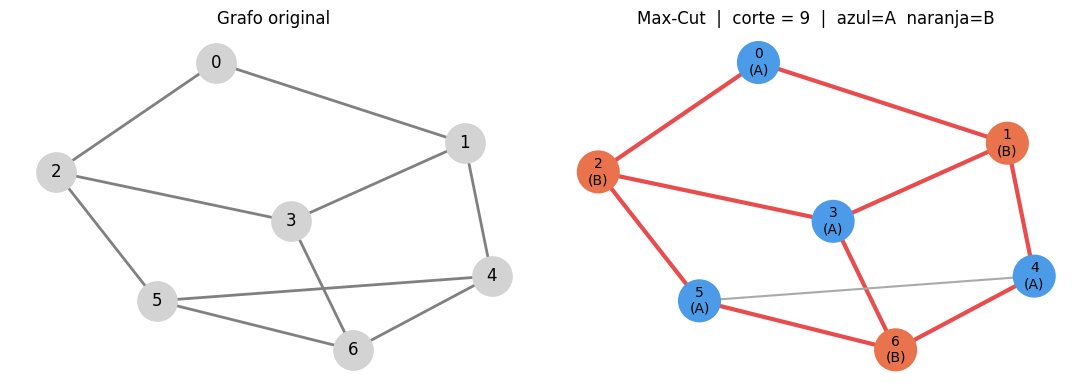

In [20]:
import networkx as nx
import matplotlib.pyplot as plt

# ── Construimos el grafo con la misma estructura que usó el solver ──────────────
G = nx.Graph()
G.add_nodes_from(nodos)          # añadimos los nodos definidos en el ejercicio
G.add_edges_from(aristas)        # añadimos todas las aristas del grafo
pos = nx.spring_layout(G, seed=42)  # posición fija (seed) para reproducibilidad

# ── Colores y etiquetas según la partición obtenida ────────────────────────────
# config[i] == 0 → grupo A (azul);  config[i] == 1 → grupo B (naranja)
colores = ["#4C9BE8" if config[i] == 0 else "#E8734C" for i in nodos]
etiquetas = {i: f"{i}\n({'A' if config[i]==0 else 'B'})" for i in nodos}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# ── Panel izquierdo: grafo original sin colorear ───────────────────────────────
nx.draw(G, pos, ax=axes[0], with_labels=True, node_color="lightgray",
        node_size=800, font_size=12, edge_color="gray", width=2)
axes[0].set_title("Grafo original")

# ── Panel derecho: partición Max-Cut ──────────────────────────────────────────
# Identificamos qué aristas cruzan la frontera A/B (aristas cortadas)
aristas_cortadas_set = set(map(frozenset, aristas_cortadas))

# Aristas cortadas → rojo;  aristas internas → gris
colores_aristas = ["#E84C4C" if frozenset([u, v]) in aristas_cortadas_set else "#AAAAAA"
                   for u, v in G.edges()]
# Aristas cortadas más gruesas para resaltarlas visualmente
anchos_aristas = [3 if frozenset([u, v]) in aristas_cortadas_set else 1.5
                  for u, v in G.edges()]

nx.draw(G, pos, ax=axes[1], labels=etiquetas, node_color=colores,
        node_size=900, font_size=10, edge_color=colores_aristas, width=anchos_aristas)
axes[1].set_title(f"Max-Cut  |  corte = {len(aristas_cortadas)}  |  azul=A  naranja=B")

plt.tight_layout()
plt.show()

### 8. Interpretación del resultado

- **Corte óptimo = 9**: el grafo tiene 10 aristas; el máximo corte es **9** porque el grafo **no es bipartito** (contiene el ciclo impar de longitud 5: 0 — 1 — 4 — 5 — 2 — 0). La única arista que queda sin cortar en la solución óptima es **4 — 5** (ambos extremos caen en el grupo A cuando la partición es A = {0, 3, 4, 5}, B = {1, 2, 6}).
- **Partición óptima**: `A = {0, 3, 4, 5}` y `B = {1, 2, 6}`, es decir, `bits = 0110001`.
- **Energía H = −9**: `H.compute(config)` devuelve −9, que coincide con el negativo del número de aristas cortadas.
- **Sin penalización**: no existe restricción adicional; cualquier energía negativa indica un corte positivo. Cuanto más negativa, mejor.
- **Simetría**: las particiones complementarias (`bits = 0110001` y `bits = 1001110`) producen exactamente el mismo corte de 9; ambas son igualmente óptimas.

> **Claves de verificación:**
> 1. `H.compute(config)` debe devolver `−len(aristas_cortadas)` (en este caso, −9).
> 2. Verificar que la única arista no cortada es **4 — 5** (ambos nodos en el mismo grupo).
> 3. Comprobar que cambiar cualquier nodo de grupo no mejora el corte (condición de optimalidad local).

---
# Ejercicio básico 5 — Reparto de tareas

### 1. Problema real

Queremos asignar **3 tareas** a **2 personas** minimizando el coste total de asignación.

| Tarea | Ana | Beñat |
|---|---:|---:|
| DNS | 4 | 5 |
| VLAN | 6 | 2 |
| Backup | 3 | 7 |

La asignación óptima evidente: **Ana→DNS, Beñat→VLAN, Ana→Backup** (coste 4+2+3=9), pero el solver debe confirmarlo.

---

### 2. Variables binarias

Una variable por pareja **(persona, tarea)**:

$x_{p,t} = 1 \Leftrightarrow \text{la persona } p \text{ realiza la tarea } t$

Con 2 personas y 3 tareas se necesitan **6 variables**. El índice de bit es $p \cdot 3 + t$.

---

### 3. Objetivo

Minimizar el coste total de asignación:

$H_{\text{objetivo}} = \sum_{p,t} \text{coste}_{p,t}\, x_{p,t}$

(Ya es una minimización directa; no hace falta cambiar el signo.)

---

### 4. Restricción o penalización

Cada tarea debe asignarse a **exactamente una** persona:

$\sum_p x_{p,t} = 1 \quad \forall t$

Penalización:

$H_{\text{restricción}} = P \sum_t \left(\sum_p x_{p,t} - 1\right)^2$

Elegimos `P = 20`, suficientemente mayor que la diferencia máxima de coste entre personas para cualquier tarea (`|7-3| = 4` para Backup).


### 5. Funciones DADK usadas en este ejercicio

| Función / atributo | Uso en el reparto de tareas |
|---|---|
| `idx(p, t)` | Transforma la pareja `(persona, tarea)` en un índice de bit ($p \cdot \text{n\_tareas} + t$) |
| `Term(1, idx(p, t))` | Crea la variable $x_{p,t}$ |
| `costes[p][t] * x(p, t)` | Añade el coste de asignar la tarea `t` a la persona `p` |
| `BinPol.sum(...)` | Suma los costes de todas las combinaciones persona-tarea |
| `(BinPol.sum(x(p,t) for p) - 1)**2` | Penaliza que una tarea no tenga persona asignada o tenga más de una |
| `configuration[idx(p,t)]` | Lee si la persona `p` está asignada a la tarea `t` |
| `restriccion.compute(config)` | Verifica que todas las tareas están asignadas correctamente (debe ser 0) |


In [21]:
# ── Código Python completo y comentado ──────────────────────────────
# Ejercicio 5 — Reparto de tareas con DADK 3.11
#
# OBJETIVO DEL EJERCICIO:
# Asignar n_tareas tareas a n_personas personas minimizando el coste total,
# con la restricción de que cada tarea sea asignada a exactamente una persona.
# Es el Problema de Asignación Lineal (LAP), resoluble en tiempo polinomial
# con el algoritmo húngaro, pero aquí lo formulamos como QUBO para practicar.
#


from dadk.BinPol import BinPol, Term
from dadk.QUBOSolverCPU import QUBOSolverCPU

# ── DATOS ─────────────────────────────────────────────────────────────────────
personas = ["Ana", "Beñat"]
tareas   = ["DNS", "VLAN", "Backup"]

# Matriz de costes: costes[p][t] = coste de que la persona p realice la tarea t.
# Coste puede representar tiempo, dificultad estimada o coste económico.
costes = [
    [4, 6, 3],   # Ana:   DNS=4, VLAN=6, Backup=3  → Ana es mejor en DNS y Backup
    [5, 2, 7],   # Beñat: DNS=5, VLAN=2, Backup=7  → Beñat es mejor en VLAN
]

# P debe superar la diferencia máxima de coste entre personas para cualquier tarea.
# Diferencia máxima: |7 − 3| = 4 (tarea Backup). P=20 >> 4 → restricción dominante.
P = 20

num_personas = len(personas)   # 2
num_tareas   = len(tareas)     # 3

# ── FUNCIONES DE ÍNDICE ───────────────────────────────────────────────────────
# Necesitamos num_personas × num_tareas = 2×3 = 6 variables binarias.
# Mapeamos la pareja (persona p, tarea t) a un índice lineal de bit:
#   (Ana, DNS)=0  (Ana, VLAN)=1  (Ana, Backup)=2
#   (Beñat,DNS)=3 (Beñat,VLAN)=4 (Beñat,Backup)=5
def idx(p, t):
    """Convierte la pareja (persona p, tarea t) en un índice lineal de bit."""
    return p * num_tareas + t

# x(p, t) = 1 si la persona p realiza la tarea t, 0 si no.
def x(p, t):
    return Term(1, idx(p, t))

# ── OBJETIVO ──────────────────────────────────────────────────────────────────
# Minimizar el coste total de todas las asignaciones activas (x=1).
# Aquí no hay cambio de signo: ya es una minimización directa de costes.
# H_obj = Σ_{p,t} costes[p][t] · x(p,t)
objetivo = BinPol.sum(
    costes[p][t] * x(p, t)
    for p in range(num_personas)
    for t in range(num_tareas)
)

# ── RESTRICCIÓN: CADA TAREA ASIGNADA A EXACTAMENTE UNA PERSONA ────────────────
# Para cada tarea t:  Σ_p x(p,t) = 1
# Penalización cuadrática:  P · (Σ_p x(p,t) − 1)²
#
# Verificación para la tarea DNS (t=0):
#   Ana=0, Beñat=0 → (0+0−1)²=1 → penaliza (tarea sin asignar) ✗
#   Ana=1, Beñat=0 → (1+0−1)²=0 → no penaliza ✓
#   Ana=0, Beñat=1 → (0+1−1)²=0 → no penaliza ✓
#   Ana=1, Beñat=1 → (1+1−1)²=1 → penaliza (dos personas para la misma tarea) ✗
restriccion = P * BinPol.sum(
    (BinPol.sum(x(p, t) for p in range(num_personas)) - 1) ** 2
    for t in range(num_tareas)   # una restricción independiente por cada tarea
)

# ── HAMILTONIANO ──────────────────────────────────────────────────────────────
H = objetivo + restriccion
print(f"Hamiltoniano de asignación creado con {H.N} bits")
print(f"({num_personas} personas × {num_tareas} tareas = {num_personas*num_tareas} bits)")

# ── SOLVER ────────────────────────────────────────────────────────────────────
# Espacio de búsqueda: 2^6 = 64 configuraciones posibles.
# Soluciones factibles: aquellas donde cada tarea tiene exactamente una persona.
# Número de soluciones factibles: num_personas^num_tareas = 2^3 = 8.
number_runs = 8
solver = QUBOSolverCPU(
    number_runs=number_runs,
    number_iterations=700,
    scaling_bit_precision=48
)
solution_list = solver.minimize(H)
mejor  = solution_list.min_solution
config = mejor.configuration   # dict con 6 bits indexados por idx(p,t)

# ── INTERPRETACIÓN DEL RESULTADO ──────────────────────────────────────────────
# Para cada tarea buscamos qué persona tiene el bit activo (x(p,t)=1).
asignaciones = []
coste_total  = 0
for t in range(num_tareas):
    asignada = None
    for p in range(num_personas):
        if config[idx(p, t)] == 1:
            asignada = p               # persona p tiene asignada la tarea t
            coste_total += costes[p][t]
    asignaciones.append((tareas[t], personas[asignada] if asignada is not None else "SIN ASIGNAR"))

print("\nRESULTADO REPARTO DE TAREAS")
print("=" * 60)
for tarea, persona in asignaciones:
    t_idx    = tareas.index(tarea)
    p_idx    = personas.index(persona) if persona in personas else -1
    coste_t  = costes[p_idx][t_idx] if p_idx >= 0 else "?"
    print(f"  {tarea:>8} → {persona:<8}  (coste: {coste_t})")
print(f"Coste total    : {coste_total}")   # solución óptima esperada: 4+2+3 = 9

# Penalización = 0 confirma que cada tarea fue asignada a exactamente una persona.
print(f"Penalización   : {restriccion.compute(config)}")
# H.compute(config) devuelve la energía real; debe igualar el coste total si la restricción se cumple.
print(f"Energía H      : {H.compute(config)}")
print(f"Frecuencia     : {int(mejor.frequency)} de {number_runs} runs")

# ── MATRIZ PERSONA-TAREA ──────────────────────────────────────────────────────
# La matriz de asignación debe tener exactamente un 1 por columna (una persona por tarea).
# Si alguna columna tiene 0 o 2 unos, la restricción fue incumplida.
print("\nMatriz x_{persona, tarea}:")
print("          " + "  ".join(f"{t:>8}" for t in tareas))
for p in range(num_personas):
    fila = [str(config[idx(p, t)]) for t in range(num_tareas)]
    # Un 1 en la posición (p,t) indica que la persona p realiza la tarea t.
    print(f"{personas[p]:>8}: " + "  ".join(f"{v:>8}" for v in fila))

Hamiltoniano de asignación creado con 6 bits
(2 personas × 3 tareas = 6 bits)

RESULTADO REPARTO DE TAREAS
       DNS → Ana       (coste: 4)
      VLAN → Beñat     (coste: 2)
    Backup → Ana       (coste: 3)
Coste total    : 9
Penalización   : 0
Energía H      : 9
Frecuencia     : 8 de 8 runs

Matriz x_{persona, tarea}:
               DNS      VLAN    Backup
     Ana:        1         0         1
   Beñat:        0         1         0


### 7. Interpretación del resultado

- **Asignación óptima esperada**: Ana→DNS (4), Beñat→VLAN (2), Ana→Backup (3) → **coste total 9**.
- **Penalización = 0**: las 3 tareas tienen exactamente una persona asignada. Si fuera > 0 significaría que alguna tarea quedó sin asignar o fue asignada a las dos personas.
- **Energía H = coste_total** cuando la penalización es 0 (el objetivo es el propio coste, sin negativo).
- **Matriz persona-tarea**: debe tener exactamente un `1` por columna (una persona por tarea). Puede haber columnas de persona con 0 o 2 unos si la restricción se viola.

> **Claves de verificación:**
> 1. `restriccion.compute(config)` debe ser `0.0`.
> 2. Suma de cada columna de la matriz = 1.
> 3. `mejor.energy` = suma de los costes de las asignaciones elegidas.


---
# Ejercicio básico 6 — Number Partitioning

### 1. Problema real

Tenemos el conjunto de números:

$\{3,\; 5,\; 6,\; 10\}$

Queremos dividirlos en **dos grupos** cuyas sumas sean lo más iguales posible.

La suma total es $S_T = 3+5+6+10 = 24$. La partición perfecta equilibrada tendría $S_A = S_B = 12$. ¿Existe tal partición?

---

### 2. Variables binarias

Una variable por número:

$x_i = 1 \Rightarrow \text{número } i \text{ va al grupo A}$

$x_i = 0 \Rightarrow \text{número } i \text{ va al grupo B}$

Cada número pertenece automáticamente a un grupo por el valor del bit, sin restricciones adicionales.

---

### 3. Objetivo

Suma del grupo A:

$S_A = \sum_i n_i\, x_i$

Suma del grupo B:

$S_B = S_T - S_A$

Diferencia entre grupos:

$S_A - S_B = 2S_A - S_T$

Queremos minimizar el cuadrado de esa diferencia:

$H = (2S_A - S_T)^2$

Cuando $S_A = S_B = 12$ la energía es **0** (diferencia nula, partición perfecta).

---

### 4. Restricción o penalización

**No hay restricciones adicionales.** Todo el hamiltoniano es objetivo. El problema es auto-restringido: si $x_i = 1$ el número va a A, si $x_i = 0$ va a B. No pueden quedar números sin grupo.


### 5. Funciones DADK usadas en este ejercicio

| Función / atributo | Uso en Number Partitioning |
|---|---|
| `Term(1, i)` | Crea una variable binaria por número del conjunto |
| `BinPol.sum(numeros[i] * x[i] ...)` | Calcula simbólicamente la suma del grupo A |
| `2 * suma_A - suma_total` | Expresión lineal que representa la diferencia entre grupos |
| `(2*suma_A - suma_total)**2` | Hamiltoniano cuadrático: su mínimo es 0 cuando los grupos están equilibrados |
| `solver.minimize(H)` | Busca la partición que minimiza la diferencia al cuadrado |
| `configuration[i]` | Indica si el número `i` va al grupo A (`1`) o al grupo B (`0`) |
| `mejor.energy` | Valor de $(2S_A - S_T)^2$; si es `0.0`, la partición es perfectamente equilibrada |

> Este es el ejercicio más compacto del conjunto: un solo término cuadrático sin ninguna penalización.


In [22]:
# ── SECCIÓN 6: Código Python completo y comentado ──────────────────────────────
# Ejercicio 6 — Number Partitioning con DADK 3.11
#
# OBJETIVO DEL EJERCICIO:
# Dividir un conjunto de números en dos grupos (A y B) tal que la diferencia
# entre la suma de ambos grupos sea mínima (idealmente = 0).
# Number Partitioning es NP-completo en su forma de decisión.
#


from dadk.BinPol import BinPol, Term
from dadk.QUBOSolverCPU import QUBOSolverCPU

# ── DATOS ─────────────────────────────────────────────────────────────────────
numeros    = [3, 5, 6, 10]   # valores a repartir entre los dos grupos
n          = len(numeros)    # 4 números → 4 bits
suma_total = sum(numeros)    # suma_total = 24; para equilibrio perfecto cada grupo = 12

# ── VARIABLES BINARIAS ────────────────────────────────────────────────────────
# x[i] = 1 → el número numeros[i] va al GRUPO A
# x[i] = 0 → el número numeros[i] va al GRUPO B
# Con 4 números hay 2^4 = 16 posibles repartos.
x = [Term(1, i) for i in range(n)]

# ── HAMILTONIANO ──────────────────────────────────────────────────────────────
# Derivación matemática:
#   suma_A = Σ numeros[i] · x[i]          (suma del grupo A)
#   suma_B = suma_total − suma_A           (suma del grupo B, no necesita bits extra)
#   diferencia = suma_A − suma_B
#              = suma_A − (suma_total − suma_A)
#              = 2·suma_A − suma_total
#
# Objetivo: minimizar |diferencia| = |2·suma_A − suma_total|
# En QUBO minimizamos el cuadrado (equivalente, ya que (dif=0) ⟺ (dif²=0)):
#   H = (2·suma_A − suma_total)²
#
# Mínimo global: H = 0  ⟺  suma_A = suma_total / 2 = 12
# No requiere penalización: H ya es 0 en la solución óptima y positivo en el resto.
suma_A = BinPol.sum(numeros[i] * x[i] for i in range(n))
H = (2 * suma_A - suma_total) ** 2

print(f"Hamiltoniano Number Partitioning creado con {H.N} bits")
print(f"Suma total: {suma_total}  |  Objetivo: suma A = {suma_total//2}")

# ── SOLVER ────────────────────────────────────────────────────────────────────
# No hay restricciones adicionales: toda configuración binaria es factible.
# El solver simplemente busca el mínimo de H = (2·suma_A − suma_total)².
number_runs = 8
solver = QUBOSolverCPU(
    number_runs=number_runs,
    number_iterations=500,
    scaling_bit_precision=48
)
solution_list = solver.minimize(H)
mejor  = solution_list.min_solution
config = mejor.configuration   # dict {bit: 0_o_1}

# ── INTERPRETACIÓN DEL RESULTADO ──────────────────────────────────────────────
# Separamos los números en grupo A (bit=1) y grupo B (bit=0).
grupo_A     = [numeros[i] for i in range(n) if config[i] == 1]
grupo_B     = [numeros[i] for i in range(n) if config[i] == 0]
suma_A_real = sum(grupo_A)
suma_B_real = sum(grupo_B)
diferencia  = abs(suma_A_real - suma_B_real)

print("\nRESULTADO NUMBER PARTITIONING")
print("=" * 60)
print(f"Grupo A: {grupo_A}  →  suma {suma_A_real}")
print(f"Grupo B: {grupo_B}  →  suma {suma_B_real}")
print(f"Diferencia absoluta: {diferencia}")
# H.compute(config) devuelve la energía real (= diferencia²).
# Si diferencia=0 → H=0 (equilibrio perfecto).
print(f"Energía H (= diferencia²): {H.compute(config)}")
print(f"Frecuencia: {int(mejor.frequency)} de {number_runs} runs")
if diferencia == 0:
    print("✓ Partición perfectamente equilibrada")
else:
    # Para este conjunto de números puede no existir partición con diferencia 0
    # (depende de si suma_total es par y de si hay subconjunto que sume exactamente la mitad).
    print(f"  La mejor partición posible tiene diferencia {diferencia}")

# ── TABLA DE SOLUCIONES ───────────────────────────────────────────────────────
# La tabla permite ver todas las particiones y su desequilibrio.
# Las filas con dif=0 son particiones perfectas; con dif pequeña, cuasi-óptimas.
print("\nSoluciones encontradas:")
print(f"{'bits':>6} {'grupo A':>18} {'suma A':>8} {'suma B':>8} {'dif':>5} {'H':>8} {'freq':>6}")
print("-" * 62)
for sol in solution_list.solutions[:8]:
    cfg  = sol.configuration
    gA   = [numeros[i] for i in range(n) if cfg[i] == 1]
    sA   = sum(gA)
    sB   = suma_total - sA                 # suma B = total − suma A (no necesita leer bits)
    bits = ''.join(str(cfg[i]) for i in range(n))  # representación binaria de la partición
    # dif = |sA − sB| = |2·sA − suma_total|; coincide con sqrt(H) si H = dif².
    # H.compute() devuelve la energía real; sol.energy es la versión escalada internamente.
    print(f"{bits:>6} {str(gA):>18} {sA:>8} {sB:>8} {abs(sA-sB):>5} {H.compute(sol.configuration):>8.1f} {int(sol.frequency):>6}")

Hamiltoniano Number Partitioning creado con 4 bits
Suma total: 24  |  Objetivo: suma A = 12

RESULTADO NUMBER PARTITIONING
Grupo A: [3, 10]  →  suma 13
Grupo B: [5, 6]  →  suma 11
Diferencia absoluta: 2
Energía H (= diferencia²): 4
Frecuencia: 3 de 8 runs
  La mejor partición posible tiene diferencia 2

Soluciones encontradas:
  bits            grupo A   suma A   suma B   dif        H   freq
--------------------------------------------------------------
  1001            [3, 10]       13       11     2      4.0      3
  0110             [5, 6]       11       13     2      4.0      5


### 7. Interpretación del resultado

Con $\{3, 5, 6, 10\}$ y $S_T = 24$, una partición perfecta necesitaría $S_A = S_B = 12$. Verificando todas las biparticiones de 4 elementos:

| Grupo A | Grupo B | $S_A$ | $S_B$ | Diferencia |
|---|---|---:|---:|---:|
| {3, 10} | {5, 6} | 13 | 11 | **2** |
| {5, 6} | {3, 10} | 11 | 13 | **2** |
| {6, 10} | {3, 5} | 16 | 8 | 8 |
| {3, 5, 6} | {10} | 14 | 10 | 4 |
| ... | ... | ... | ... | ... |

La mejor partición posible tiene **diferencia = 2** (A={3,10}, B={5,6}), lo que produce $H = 2^2 = 4$.

- **Energía H = 4**: no existe partición perfecta para este conjunto; el mínimo alcanzable es 4.
- **Grupo A = {3, 10}, Grupo B = {5, 6}** (o su complemento): ambas soluciones simétricas son equivalentes y el solver puede devolver cualquiera de las dos.
- **Sin penalización**: la energía es directamente $(S_A - S_B)^2$. No hay restricciones que puedan incumplir la factibilidad; cualquier asignación de bits es válida.

> **Claves de verificación:**
> 1. `mejor.energy` = $(|S_A - S_B|)^2$. Para este ejemplo debe ser `4.0`.
> 2. `suma_A_real + suma_B_real` debe igualar `suma_total` = 24.
> 3. Las soluciones con `bits = 1001` y `bits = 0110` tienen la misma energía por simetría.
